In [1]:
import numpy as np
import xarray as xr
import pyproj
from pyresample.geometry import SwathDefinition
import pyresample.kd_tree as kd_tree
from pyresample import get_area_def

In [ ]:
import os
import xarray as xr
import numpy as np
import subprocess
import time
import threading
from multiprocessing import Pool
from functools import partial
from glaciation_time_estimator.auxiliary_func.config_reader import read_config
from glaciation_time_estimator.auxiliary_func.Helper_fun import generate_temp_range
from glaciation_time_estimator.data_preprocessing.Resample_data import ProjectionTransformer
from glaciation_time_estimator.data_preprocessing.File_name_generator import generate_filename_dict
from glaciation_time_estimator.data_preprocessing.Output_file_generation import OutputResampledFile
import warnings

In [38]:
sat_data_cpp=xr.open_mfdataset("/wolke_scratch/dnikolo/CLAAS_Data/np/2021/01/02/CPPin2021010*.nc")

In [39]:
sat_data_cpp

<xarray.Dataset> Size: 25GB
Dimensions:                  (time: 96, y: 896, x: 3133, nx: 3133, ny: 896)
Coordinates:
  * time                     (time) datetime64[ns] 768B 2021-01-02 ... 2021-0...
  * x                        (x) float64 25kB -0.1313 -0.1312 ... 0.1312 0.1313
  * y                        (y) float64 7kB 0.1513 0.1513 ... 0.07638 0.0763
  * nx                       (nx) uint16 6kB 290 291 292 293 ... 3420 3421 3422
  * ny                       (ny) uint16 2kB 51 52 53 54 55 ... 943 944 945 946
Data variables: (12/30)
    cot_16                   (time, y, x) float32 1GB dask.array<chunksize=(1, 896, 1856), meta=np.ndarray>
    cot_16_unc               (time, y, x) float32 1GB dask.array<chunksize=(1, 896, 1856), meta=np.ndarray>
    cre_16                   (time, y, x) float32 1GB dask.array<chunksize=(1, 896, 1856), meta=np.ndarray>
    cre_16_unc               (time, y, x) float32 1GB dask.array<chunksize=(1, 896, 1856), meta=np.ndarray>
    cwp_16                   (time, y, x) float32 1GB dask.array<chunksize=(1, 896, 1856), meta=np.ndarray>
    cwp_16_unc               (time, y, x) float32 1GB dask.array<chunksize=(1, 896, 1856), meta=np.ndarray>
    ...                       ...
    platform_flag            (time) float32 384B dask.array<chunksize=(1,), meta=np.ndarray>
    subsatellite_lon         (time) float64 768B dask.array<chunksize=(1,), meta=np.ndarray>
    subsatellite_lat         (time) float64 768B dask.array<chunksize=(1,), meta=np.ndarray>
    subsatellite_alt         (time) float64 768B dask.array<chunksize=(1,), meta=np.ndarray>
    georef_offset_corrected  (time) int8 96B dask.array<chunksize=(1,), meta=np.ndarray>
    projection               (time) int8 96B 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0
Attributes: (12/45)
    filename:                                        CPPin20210102000000405SV...
    title:                                           ICDR of CM SAF CLoud pro...
    summary:                                         This file contains Cloud...
    comment:                                         Data in this file are st...
    creator_name:                                    DE/DWD
    creator_email:                                   contact.cmsaf@dwd.de
    ...                                              ...
    variable_id:                                     cwp,cot,cre,cdnc,cgt,cph
    id:                                              DOI:10.5676/EUM_SAF_CM/C...
    references:                                      https://doi.org/10.5676/...
    license:                                         The CM SAF data are owne...
    history:                                         Sun Dec  1 04:43:24 2024...
    NCO:                                             netCDF Operators version...

In [3]:
sat_data_cpp=xr.load_dataset("/wolke_scratch/dnikolo/CLAAS_Data/np/2021/01/02/CPPin20210102001500405SVMSGI1MD.nc")
sat_data_ctx=xr.load_dataset("/wolke_scratch/dnikolo/CLAAS_Data/np/2021/01/02/CTXin20210102001500405SVMSGI1MD.nc")
aux_data=xr.load_dataset("/wolke_scratch/dnikolo/CLAAS_Data/np/CM_SAF_CLAAS3_L2_AUX.nc",decode_times=False)

In [ ]:
class ProjectionTransformer():
    def __init__(self):
        self.AreaDef = None
        self.SwathDef = None
        self._neighbor_info = None
        self._neighbor_params = None  # (radius, epsilon, neighbours)

    def generate_lat_lon_prj(self, aux_data):
        lon_mat = aux_data["lon"][0, :, :].values
        lat_mat = aux_data["lat"][0, :, :].values

        self.bounds = [np.nanmin(lon_mat.astype(np.float64)),
                       np.nanmax(lon_mat.astype(np.float64)),
                       np.nanmin(lat_mat.astype(np.float64)),
                       np.nanmax(lat_mat.astype(np.float64))]
        print(f"Bounds = {self.bounds}")

        Proj4Args = (
            '+proj=eqc +lat_ts=0 +lat_0=0 +lon_0=0 +x_0=0 +y_0=0 '
            '+a=6378.137 +b=6378.137 +units=km'
        )
        Prj = pyproj.Proj(Proj4Args)
        AreaID = AreaName = ProjID = 'cyl'

        self.ny, self.nx = lon_mat.shape

        SW = Prj(self.bounds[0], self.bounds[2])
        NW = Prj(self.bounds[1], self.bounds[3])
        area_extent = [SW[0], SW[1], NW[0], NW[1]]

        self.AreaDef = get_area_def(AreaID, AreaName, ProjID, Proj4Args,
                                    self.nx, self.ny, area_extent)
        self.SwathDef = SwathDefinition(lons=lon_mat, lats=lat_mat)

        # Invalidate any old neighbor cache if geometry changed
        self._neighbor_info = None
        self._neighbor_params = None

        self._generate_new_coordinates()

    def _generate_new_coordinates(self):
        self.new_cord_lon = np.linspace(self.bounds[0], self.bounds[1], self.nx)
        self.new_cord_lat = np.linspace(self.bounds[2], self.bounds[3], self.ny)

    # --- New: build, use, and persist neighbor cache -------------------------

    def build_neighbor_cache(self, radius_of_influence=60000, epsilon=5, neighbours=1):
        """Precompute and cache neighbor info for later fast resampling."""
        if self.SwathDef is None or self.AreaDef is None:
            raise RuntimeError("Call generate_lat_lon_prj(...) before caching neighbors.")
        info = kd_tree.get_neighbour_info(
            self.SwathDef, self.AreaDef,
            radius_of_influence=radius_of_influence,
            neighbours=neighbours,
            epsilon=epsilon
        )
        self._neighbor_info = info
        self._neighbor_params = (radius_of_influence, epsilon, neighbours)

    def save_neighbor_cache(self, path):
        """Persist the cached neighbor info to disk."""
        if self._neighbor_info is None:
            raise RuntimeError("No neighbor cache to save. Call build_neighbor_cache() first.")
        vi, vo, ia, da = self._neighbor_info
        roi, eps, neigh = self._neighbor_params
        np.savez_compressed(path, vi=vi, vo=vo, ia=ia, da=da,
                            roi=roi, eps=eps, neigh=neigh,
                            nx=self.nx, ny=self.ny)

    def load_neighbor_cache(self, path):
        """Load neighbor info from disk (must match current geometry)."""
        z = np.load(path, allow_pickle=False)
        # Basic sanity checks
        if (int(z["nx"]) != self.nx) or (int(z["ny"]) != self.ny):
            raise ValueError("Cached neighbor grid size does not match current geometry.")
        self._neighbor_info = (z["vi"], z["vo"], z["ia"], z["da"])
        self._neighbor_params = (int(z["roi"]), int(z["eps"]), int(z["neigh"]))

    # -------------------------------------------------------------------------

    def remap_data(self, var_field, n_resample_procs=8,
                   radius_of_influence=60000, epsilon=5):
        if self.SwathDef is None:
            raise RuntimeError(
                "No projection parameters. Run generate_lat_lon_prj(...) first."
            )

        if len(var_field.shape) != 3:
            raise NotImplementedError("2D var field remapping not yet added")

        # Data as (y, x, time)
        data = var_field.transpose("y", "x", "time").values
        nt = data.shape[2]

        # If we have a matching neighbor cache, use it; else fall back
        use_cache = (
            self._neighbor_info is not None and
            self._neighbor_params == (radius_of_influence, epsilon, 1)
        )

        if use_cache:
            print("Using precomputed neighbor cache for remapping.")
            vi, vo, ia, da = self._neighbor_info
            out = kd_tree.get_sample_from_neighbour_info(
                    'nn',
                    (self.ny, self.nx),
                    data,
                    vi, vo, ia, da,
                    fill_value=-1
                )
        else:
            # Compute neighbors on the fly (slower) or pre-build via build_neighbor_cache()
            out = kd_tree.resample_nearest(
                self.SwathDef, data, self.AreaDef,
                radius_of_influence=radius_of_influence,
                fill_value=-1, epsilon=epsilon,
                nprocs=n_resample_procs
            )

        # Back to (time, y, x) and keep your original flip on Y
        out = out.transpose(2, 0, 1)
        out = np.flip(out, axis=1)
        out[np.isnan(out)] = -1
        return out
    

In [41]:
transformer = ProjectionTransformer()


In [50]:
transformer.generate_lat_lon_prj(aux_data)


Bounds = [-79.74298161940857, 79.7396484770131, 26.044719326356088, 81.07635224475464]


In [54]:
transformer.new_cord_lon[1:]-transformer.new_cord_lon[:-1]

array([0.05092038, 0.05092038, 0.05092038, ..., 0.05092038, 0.05092038,
       0.05092038])

In [33]:
transformer.build_neighbor_cache()
transformer.save_neighbor_cache("neighbor_cache_cpp.npz")

In [43]:
transformer.load_neighbor_cache("neighbor_cache_cpp.npz")

In [44]:
remaped=transformer.remap_data(sat_data_cpp["cph"])

In [45]:
import matplotlib.pyplot as plt

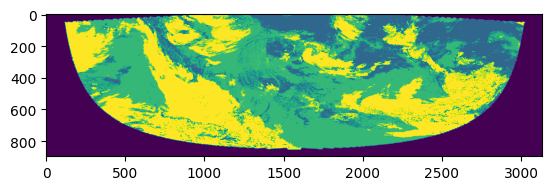

In [47]:
plt.imshow(remaped[10,:,:])